In [1]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
from qiskit_experiments.framework import ExperimentData
from qiskit_experiments.library import StandardRB
from qiskit_experiments.framework import BatchExperiment
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration of APL pi pulses on two qubits

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

In [3]:
service.backends()

[<IBMBackend('ibm_osaka')>,
 <IBMBackend('ibm_kyoto')>,
 <IBMBackend('ibm_kyiv')>,
 <IBMBackend('ibm_sherbrooke')>,
 <IBMBackend('ibm_brisbane')>,
 <IBMBackend('ibm_cusco')>,
 <IBMBackend('ibm_nazca')>,
 <IBMBackend('ibm_torino')>]

In [5]:
for backend in service.backends():
    print(backend.name, backend.num_qubits)

ibm_osaka 127
ibm_kyoto 127
ibm_kyiv 127
ibm_sherbrooke 127
ibm_brisbane 127
ibm_cusco 127
ibm_nazca 127
ibm_torino 133


Since all the backends have similar number of qubits, I'll just focus on `ibm_osaka` and choose a qubit with only two neighbors.

In [6]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_osaka")
dt = backend.configuration().dt * ns

# desired_duration = 128 # dt, apl pulses
desired_duration = 120 # dt, new pulses

granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

# Qubits to use

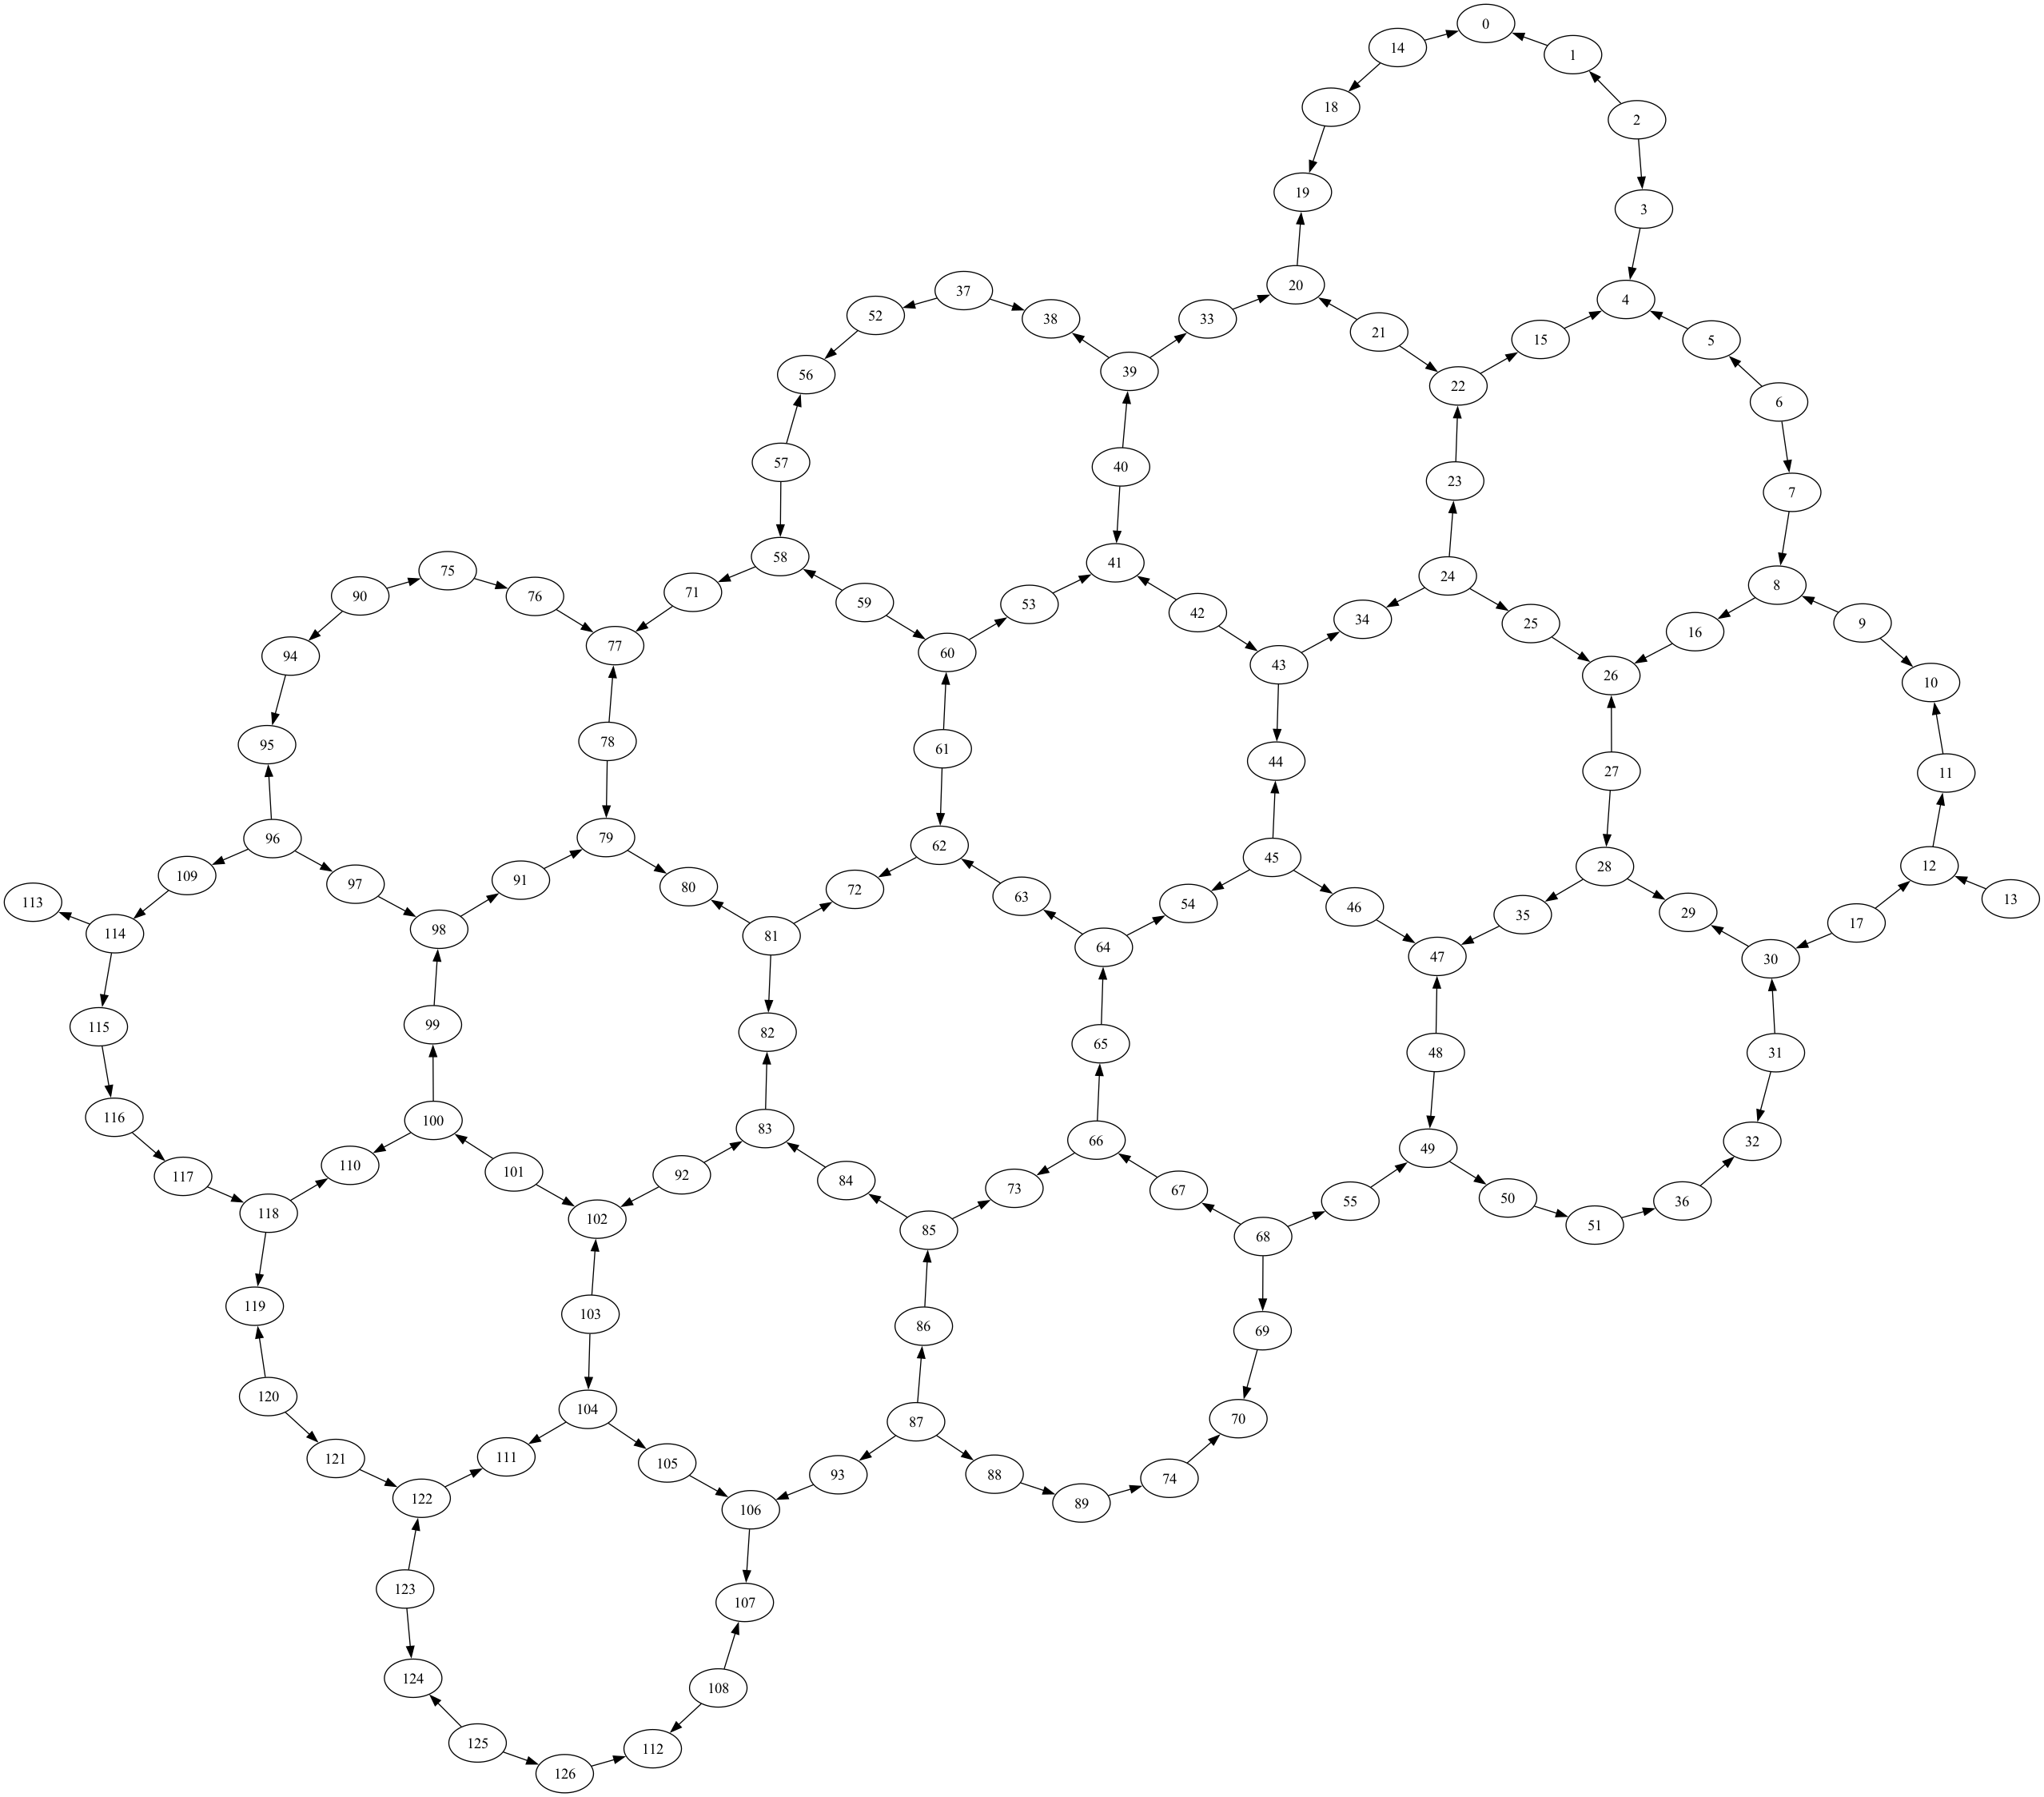

In [9]:
backend.coupling_map.draw()

In [122]:
qubit0 = 1
qubit1 = 2

In [123]:
qubit2 = 0
qubit3 = 3

In [124]:
backend.configuration().hamiltonian['vars']['jq3q4'] * GHz / 2 / np.pi

0.0020217791786945136

In [125]:
backend.properties().to_dict()['qubits'][qubit0][0], backend.properties().to_dict()['qubits'][qubit0][1]

({'date': datetime.datetime(2024, 8, 11, 13, 36, 21, tzinfo=tzlocal()),
  'name': 'T1',
  'unit': 'us',
  'value': 307.85178203993115},
 {'date': datetime.datetime(2024, 8, 11, 13, 55, 28, tzinfo=tzlocal()),
  'name': 'T2',
  'unit': 'us',
  'value': 266.44951476703653})

In [126]:
backend.properties().to_dict()['qubits'][qubit1][0], backend.properties().to_dict()['qubits'][qubit1][1]

({'date': datetime.datetime(2024, 8, 11, 13, 36, 21, tzinfo=tzlocal()),
  'name': 'T1',
  'unit': 'us',
  'value': 269.7959839504807},
 {'date': datetime.datetime(2024, 8, 11, 13, 39, 6, tzinfo=tzlocal()),
  'name': 'T2',
  'unit': 'us',
  'value': 290.82649759316996})

In [127]:
backend.status()

In [24]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")
sampler = Sampler(backend=backend, session=session)

Session id: ctwkczv46w90008renn0


# Spectator experiments

### Reset experiment

Before trying to run any stuff with our custom pulses, we will run a few experiments to test the behavior of spectator qubits. Qubit 1 will be our data qubit, while its expectators will be qubits 0 and 2. First, we run a simple reset experiment, where we reset all three qubits, add a delay of varying times, and then measure the qubits.

In [15]:
def reset_experiment(q0, q1, q2, delay_duration):
    qc = qk.QuantumCircuit(3)
    qc.reset([q0, q1, q2])
    qc.delay(delay_duration, q0)
    qc.delay(delay_duration, q1)
    qc.delay(delay_duration, q2)
    qc.measure_all()
    return qc

In [16]:
reset_experiment(0, 1, 2, 0).draw()

┌──────────────┐ ░ ┌─┐      
   q_0: ─|0>─┤ Delay(0[dt]) ├─░─┤M├──────
             ├──────────────┤ ░ └╥┘┌─┐   
   q_1: ─|0>─┤ Delay(0[dt]) ├─░──╫─┤M├───
             ├──────────────┤ ░  ║ └╥┘┌─┐
   q_2: ─|0>─┤ Delay(0[dt]) ├─░──╫──╫─┤M├
             └──────────────┘ ░  ║  ║ └╥┘
meas: 3/═════════════════════════╩══╩══╩═
                                 0  1  2

In [34]:
reset_experiments = [reset_experiment(0, 1, 2, time) for time in range(0, 500, 8)] # dt must be multiple of 8

In [35]:
reset_job = sampler.run(reset_experiments, shots=2048)

In [36]:
reset_job.job_id()

'ctwkeha46w90008rens0'

In [39]:
reset_job.status()

<JobStatus.DONE: 'job has successfully run'>

In [38]:
reset_job = service.job("ctwkeha46w90008rens0")

In [62]:
reset_results = reset_job.result()
reset_counts = []
for result in reset_results:
    reset_counts.append(result.data.meas.get_counts()['000'] / 2048)

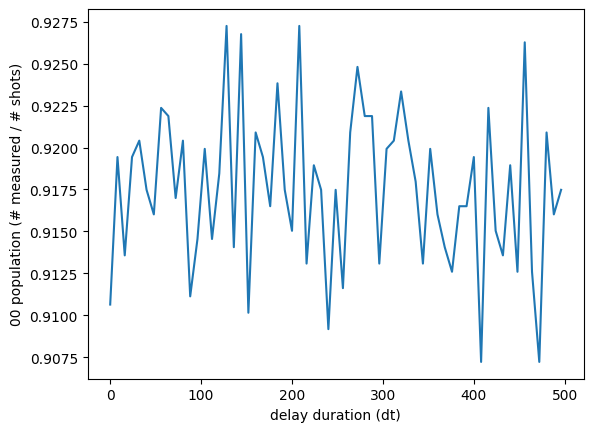

In [61]:
plt.plot(range(0, 500, 8), reset_counts)
plt.ylabel("00 population (# measured / # shots)")
plt.xlabel("delay duration (dt)")
plt.show()

### X test

Now we want to test the spectators again but while performing something more interesting in our "data" qubit, an X gate.

In [70]:
def x_experiment(q0, q1, q2, x_gates):
    qc = qk.QuantumCircuit(3)
    qc.reset([q0, q1, q2])

    for _ in range(x_gates):
        qc.x(q1)

    qc.measure_all()
    return qc

In [71]:
x_experiment(0, 1, 2, 4).draw()

░ ┌─┐      
   q_0: ─|0>──────────────────────░─┤M├──────
             ┌───┐┌───┐┌───┐┌───┐ ░ └╥┘┌─┐   
   q_1: ─|0>─┤ X ├┤ X ├┤ X ├┤ X ├─░──╫─┤M├───
             └───┘└───┘└───┘└───┘ ░  ║ └╥┘┌─┐
   q_2: ─|0>──────────────────────░──╫──╫─┤M├
                                  ░  ║  ║ └╥┘
meas: 3/═════════════════════════════╩══╩══╩═
                                     0  1  2

In [83]:
x_experiments = [x_experiment(0, 1, 2, i) for i in range(0, 200, 2)]

In [84]:
x_job = sampler.run(x_experiments, shots=2048)

In [85]:
x_job.job_id()

'ctwkr91ezn20008shmeg'

In [92]:
x_job.status()

<JobStatus.DONE: 'job has successfully run'>

In [93]:
x_job = service.job("ctwkr91ezn20008shmeg")

In [104]:
x_results = x_job.result()
x_counts = []
x_counts_0 = []
x_counts_1 = []
x_counts_2 = []
for result in x_results:
    result_0 = result
    x_counts.append(result.data.meas.get_counts()['000'] / 2048)
    x_counts_0.append(result.data.meas.slice_bits(0).get_counts()['0'] / 2048)
    x_counts_1.append(result.data.meas.slice_bits(1).get_counts()['0'] / 2048)
    x_counts_2.append(result.data.meas.slice_bits(2).get_counts()['0'] / 2048)

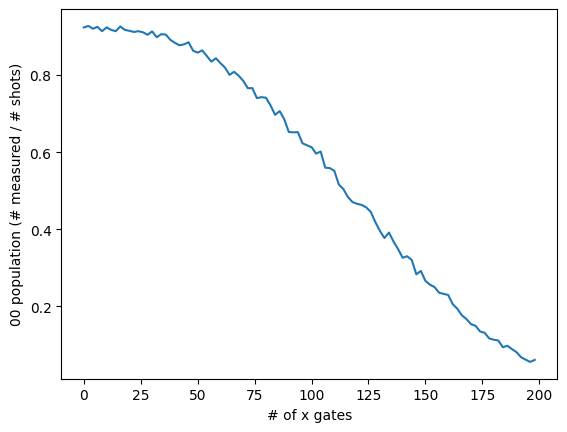

In [110]:
plt.plot(range(0, 200, 2), x_counts)
plt.ylabel("00 population (# measured / # shots)")
plt.xlabel("# of x gates")
plt.show()

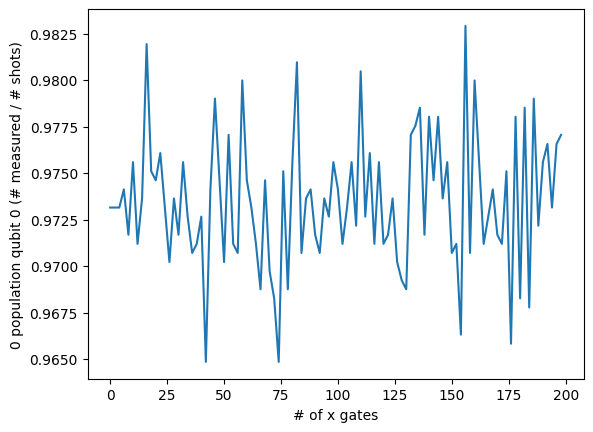

In [111]:
plt.plot(range(0, 200, 2), x_counts_0)
plt.ylabel("0 population qubit 0 (# measured / # shots)")
plt.xlabel("# of x gates")
plt.show()

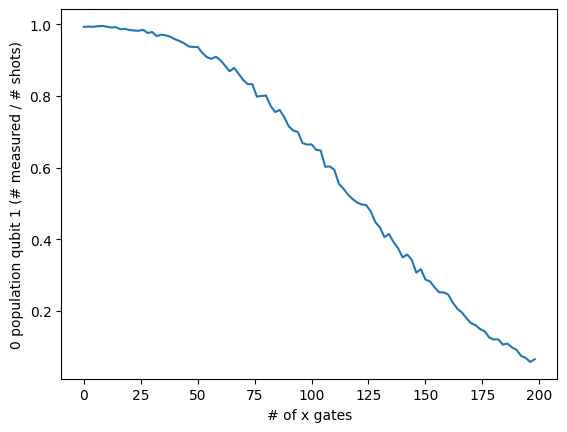

In [112]:
plt.plot(range(0, 200, 2), x_counts_1)
plt.ylabel("0 population qubit 1 (# measured / # shots)")
plt.xlabel("# of x gates")
plt.show()

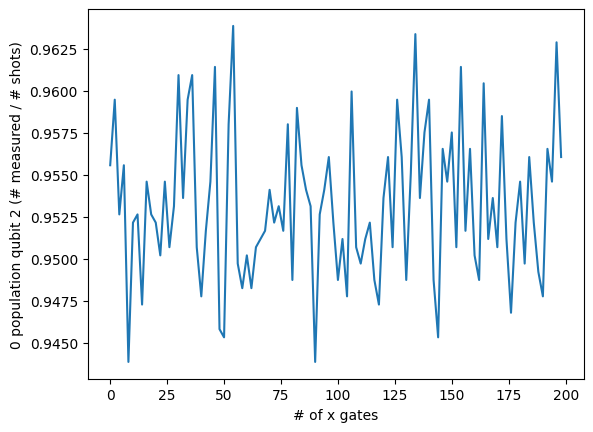

In [113]:
plt.plot(range(0, 200, 2), x_counts_2)
plt.ylabel("0 population qubit 2 (# measured / # shots)")
plt.xlabel("# of x gates")
plt.show()

# Loading our pulses

In [114]:
# pico_a = ps.from_csv(
#     "../pico-pulses/apl-pulses/x_gates.csv" # gates with 2 pi offset
# )
pico_a = ps.from_csv(
    "../pico-pulses/saved-pulses-2024-06-27/single_qubit_gateset.csv" # gates without 2 pi offset
)
pico_gates = {key: row for key, row in zip(["x1", "i1", "x2", "i2"], pico_a)}

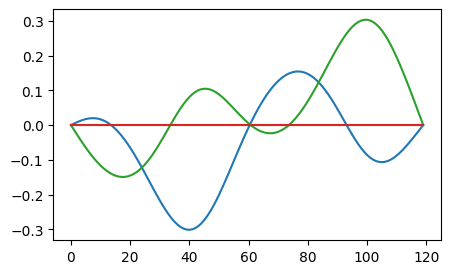

In [115]:
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_a:
    ax.plot(row)

In [116]:
np.trapz(pico_gates["x1"], dx=dt), np.trapz(pico_gates["x2"], dx=dt)

(-3.1373487889817544, 3.137413414080159)

In [117]:
default_gates = {
    "x1": np.real(ps.gaussian_envelope(duration, dt=dt, angle=np.pi).samples),
    "x2": np.real(ps.gaussian_envelope(duration, dt=dt, angle=np.pi).samples)
}

In [118]:
np.trapz(default_gates["x1"], dx=dt), np.trapz(default_gates["x2"], dx=dt)

(3.141507075143458, 3.141507075143458)

## Rough calibration

In [119]:
from qiskit.circuit import Parameter
import qiskit.pulse as pulse
from qiskit_experiments.calibration_management.calibrations import Calibrations
from qiskit_experiments.library.calibration import RoughAmplitudeCal

In [120]:
def add_sched(cals, backend, gate_key, qubit, gates) -> Calibrations:
    amp = Parameter("amp")
    channel = pulse.DriveChannel(qubit)

    with qk.pulse.build(name="x", backend=backend) as x90p:
        signal = gates[gate_key]
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        param_gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "x", amp=amp
        )
        qk.pulse.play(param_gate, channel)
    print(f"Max amplitude: {np.max(np.abs(signal_samples))}")
    cals.add_schedule(x90p, (qubit,))

In [128]:
cals = Calibrations.from_backend(backend)
add_sched(cals, backend, "x1", qubit0, pico_gates)
add_sched(cals, backend, "x2", qubit1, pico_gates)

Max amplitude: 0.3012678011173944
Max amplitude: 0.30303932801317945


In [129]:
gaussian_cals = Calibrations.from_backend(backend)
add_sched(gaussian_cals, backend, "x1", qubit0, default_gates)
add_sched(gaussian_cals, backend, "x2", qubit1, default_gates)

Max amplitude: 0.09699861422442428
Max amplitude: 0.09699861422442428


In [130]:
# set some starting value for amplitude
cals.add_parameter_value(0.5, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(0.5, Parameter("amp"), (qubit1,), "x") 

gaussian_cals.add_parameter_value(0.5, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(0.5, Parameter("amp"), (qubit1,), "x")

In [131]:
drive_amps_1 = np.linspace(-3, 3, 51)
rabi_x1 = RoughAmplitudeCal(
    physical_qubits=(qubit0,), 
    calibrations=cals, 
    backend=backend, 
    amplitudes=drive_amps_1, 
    target_angle=np.pi, 
)

drive_amps_2 = np.linspace(-3, 3, 51)
rabi_x2 = RoughAmplitudeCal(
    physical_qubits=(qubit1,), 
    calibrations=cals, 
    backend=backend, 
    amplitudes=drive_amps_2, 
    target_angle=np.pi, # 3 pi if working with offset
)

In [132]:
drive_amps_guass_1 = np.linspace(-4, 4, 51)
rabi_x1_gaussian = RoughAmplitudeCal(
    physical_qubits=(qubit0,), 
    calibrations=gaussian_cals, 
    backend=backend, 
    amplitudes=drive_amps_guass_1, 
    target_angle=np.pi, 
)

drive_amps_guass_2 = np.linspace(-4, 4, 51)
rabi_x2_gaussian = RoughAmplitudeCal(
    physical_qubits=(qubit1,), 
    calibrations=gaussian_cals, 
    backend=backend, 
    amplitudes=drive_amps_guass_2, 
    target_angle=np.pi, 
)

In [133]:
rabi_x1_data = rabi_x1.run()
rabi_x2_data = rabi_x2.run()

In [ ]:
rabi_x1_data_gaussian = rabi_x1_gaussian.run()
rabi_x2_data_gaussian = rabi_x2_gaussian.run()

In [135]:
rabi_x1_data.job_ids, rabi_x2_data.job_ids

(['ctwm0zvseb10008x57n0'], ['ctwm174ezn20008shmxg'])

In [136]:
rabi_x1_data_gaussian.job_ids, rabi_x2_data_gaussian.job_ids

(['ctwm1kpseb10008x57p0'], ['ctwm1x746w90008repyg'])

In [141]:
rabi_x1_data.job_status(), rabi_x2_data.job_status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [145]:
rabi_x1_data_gaussian.job_status(), rabi_x2_data_gaussian.job_status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [ ]:
rabi_x1_data = ExperimentData(experiment=rabi_x1)
rabi_x1_data.add_jobs([service.job("ctwm0zvseb10008x57n0")])
rabi_x1.analysis.run(rabi_x1_data, replace_results=True)

rabi_x2_data = ExperimentData(experiment=rabi_x2)
rabi_x2_data.add_jobs([service.job("ctwm174ezn20008shmxg")])
rabi_x2.analysis.run(rabi_x2_data, replace_results=True)

In [ ]:
rabi_x1_data_gaussian = ExperimentData(experiment=rabi_x1_gaussian)
rabi_x1_data_gaussian.add_jobs([service.job("ctwm1kpseb10008x57p0")])
rabi_x1_gaussian.analysis.run(rabi_x1_data_gaussian, replace_results=True)

rabi_x2_data_gaussian = ExperimentData(experiment=rabi_x2_gaussian)
rabi_x2_data_gaussian.add_jobs([service.job("ctwm1x746w90008repyg")])
rabi_x2_gaussian.analysis.run(rabi_x2_data_gaussian, replace_results=True)

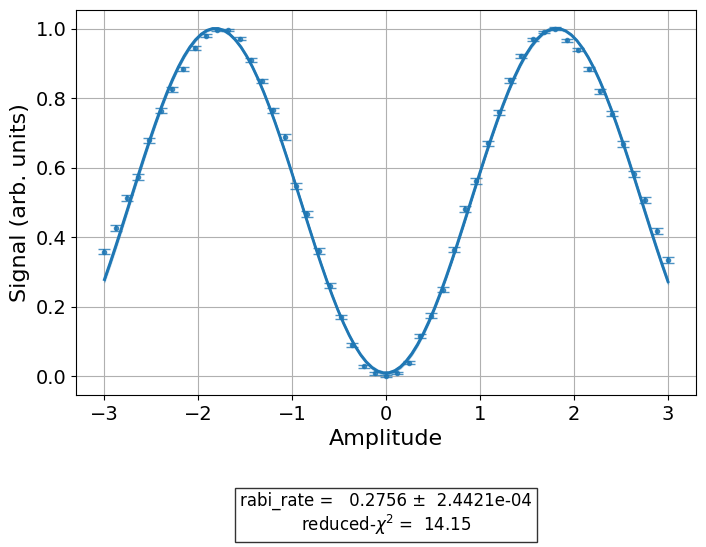

In [149]:
rabi_x1_data.block_for_results()
rabi_x1_data.figure(0)

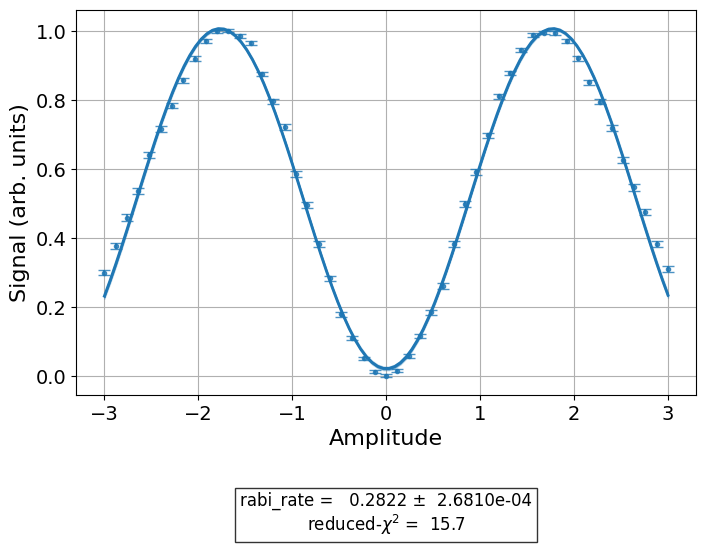

In [147]:
rabi_x2_data.block_for_results()
rabi_x2_data.figure(0)

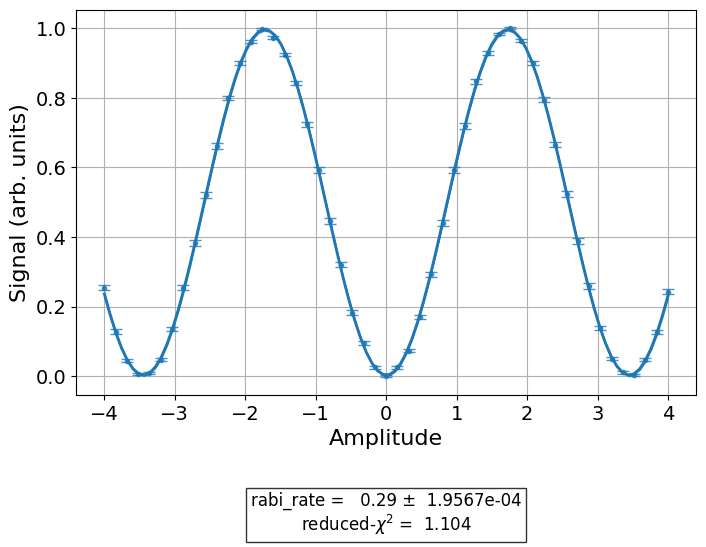

In [150]:
rabi_x1_data_gaussian.block_for_results()
rabi_x1_data_gaussian.figure(0)

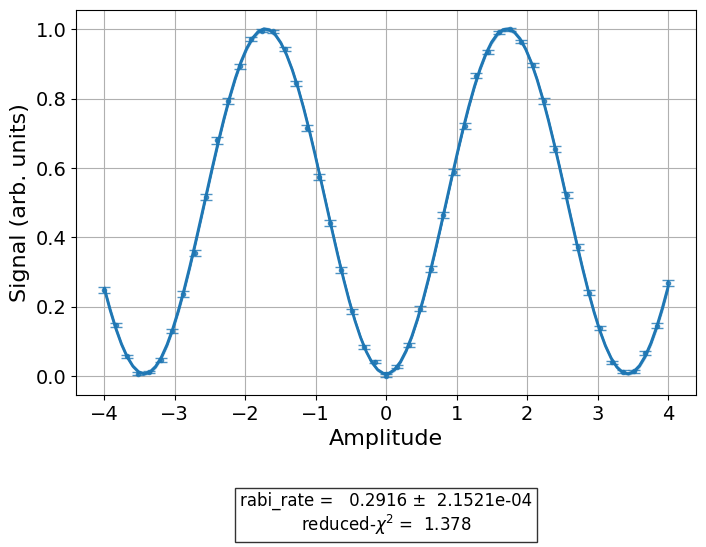

In [152]:
rabi_x2_data_gaussian.block_for_results()
rabi_x2_data_gaussian.figure(0)

In [153]:
from qiskit_experiments.calibration_management.update_library import BaseUpdater

def update_param(exp, exp_data, angle = np.pi):
    result_index = exp.experiment_options.result_index
    rate = 2 * np.pi * BaseUpdater.get_value(exp_data, exp.__outcome__, result_index)

    # angle, _, _, prev_amp = exp_data.metadata["angles_schedules"][0]
    value = np.round(angle / rate, decimals=8)
    print(f"Target angle: {angle}")
    print(f"New amplitude: {value}")
    return value

In [154]:
rough_x1_amp = update_param(rabi_x1, rabi_x1_data)
rough_x2_amp = update_param(rabi_x2, rabi_x2_data)

Target angle: 3.141592653589793
New amplitude: 1.81423248
Target angle: 3.141592653589793
New amplitude: 1.77163466


In [155]:
rough_x1_amp_gaussian = update_param(rabi_x1_gaussian, rabi_x1_data_gaussian)
rough_x2_amp_gaussian = update_param(rabi_x2_gaussian, rabi_x2_data_gaussian)

Target angle: 3.141592653589793
New amplitude: 1.72398925
Target angle: 3.141592653589793
New amplitude: 1.71486045


In [156]:
cals.add_parameter_value(rough_x1_amp, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(rough_x2_amp, Parameter("amp"), (qubit1,), "x")

In [157]:
gaussian_cals.add_parameter_value(rough_x1_amp_gaussian, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(rough_x2_amp_gaussian, Parameter("amp"), (qubit1,), "x")

In [158]:
rough_x1 = cals.get_schedule("x", (qubit0,))
rough_x2 = cals.get_schedule("x", (qubit1,))
rough_x1, rough_x2

(ScheduleBlock(Play(x(duration=120, amp=1.81423248, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.77163466, angle=0), DriveChannel(2)), name="x", transform=AlignLeft()))

In [159]:
rough_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
rough_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
rough_x1_gaussian, rough_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.72398925, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.71486045, angle=0), DriveChannel(2)), name="x", transform=AlignLeft()))

In [160]:
np.trapz(rough_x1.instructions[0][1].pulse.get_waveform().samples, dx=dt), np.trapz(rough_x2.instructions[0][1].pulse.get_waveform().samples, dx=dt)

((-5.69222066971483+0j), (5.559570081612571+0j))

In [161]:
np.trapz(rough_x1_gaussian.instructions[0][1].pulse.get_waveform().samples, dx=dt), np.trapz(rough_x2_gaussian.instructions[0][1].pulse.get_waveform().samples, dx=dt)

((5.416051641897995+0j), (5.387372778483645+0j))

# Fine calibration

In [162]:
current_x1 = cals.get_schedule("x", (qubit0,))
current_x2 = cals.get_schedule("x", (qubit1,))
current_x1, current_x2

(ScheduleBlock(Play(x(duration=120, amp=1.81423248, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.77163466, angle=0), DriveChannel(2)), name="x", transform=AlignLeft()))

In [163]:
current_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
current_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
current_x1_gaussian, current_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.72398925, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.71486045, angle=0), DriveChannel(2)), name="x", transform=AlignLeft()))

In [164]:
def get_fine_circuit(length: int, qubit: int, num_qubits: int, schedule):
    qc = qk.QuantumCircuit(num_qubits, 1)
    qc.sx(qubit)
    for _ in range(length):
        qc.x(qubit)
    qc.measure(qubit, 0)

    x_gate = qk.circuit.library.XGate()
    qc.add_calibration(x_gate, (qubit,), schedule)

    return qc

In [165]:
num_qubits = backend.num_qubits

In [166]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")
sampler = Sampler(backend=backend, session=session)

Session id: ctwm5cnv0kkg008q087g


In [167]:
lengths = range(0, 20)

In [168]:
x1_testing = [get_fine_circuit(l, qubit0, num_qubits, current_x1) for l in lengths]
x2_testing = [get_fine_circuit(l, qubit1, num_qubits, current_x2) for l in lengths]

In [169]:
x1_testing_gaussian = [get_fine_circuit(l, qubit0, num_qubits, current_x1_gaussian) for l in lengths]
x2_testing_gaussian = [get_fine_circuit(l, qubit1, num_qubits, current_x2_gaussian) for l in lengths]

In [170]:
x1_testing_job = sampler.run(x1_testing, shots=1024)
x2_testing_job = sampler.run(x2_testing, shots=1024)

In [171]:
x1_testing_job_gaussian = sampler.run(x1_testing_gaussian, shots=1024)
x2_testing_job_gaussian = sampler.run(x2_testing_gaussian, shots=1024)

In [172]:
x1_testing_job.job_id(), x2_testing_job.job_id()

('ctwm5f5ezn20008shn6g', 'ctwm5j63zkm0008sjbkg')

In [173]:
x1_testing_job_gaussian.job_id(), x2_testing_job_gaussian.job_id()

('ctwm5ny66x8g008q6wag', 'ctwm5pe66x8g008q6wb0')

In [178]:
x1_testing_job.status(), x2_testing_job.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [179]:
x1_testing_job_gaussian.status(), x2_testing_job_gaussian.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [176]:
x1_testing_job = service.job("ctwm5f5ezn20008shn6g")
x2_testing_job = service.job("ctwm5j63zkm0008sjbkg")

In [177]:
x1_testing_job_gaussian = service.job("ctwm5ny66x8g008q6wag")
x2_testing_job_gaussian = service.job("ctwm5pe66x8g008q6wb0")

In [180]:
x1_results = x1_testing_job.result()
x1_counts = []
for result in x1_results:
    x1_counts.append(result.data.c.get_counts()['1'] / 1024)

x2_results = x2_testing_job.result()
x2_counts = []
for result in x2_results:
    x2_counts.append(result.data.c.get_counts()['1'] / 1024)

In [181]:
x1_results_gaussian = x1_testing_job_gaussian.result()
x1_counts_gaussian = []
for result in x1_results_gaussian:
    x1_counts_gaussian.append(result.data.c.get_counts()['1'] / 1024)

x2_results_gaussian = x2_testing_job_gaussian.result()
x2_counts_gaussian = []
for result in x2_results_gaussian:
    x2_counts_gaussian.append(result.data.c.get_counts()['1'] / 1024)

In [182]:
def get_d_theta(counts, estimate=0.1, plot=True):
    def fit_function(x_values, y_values, function, init_params):
        fitparams, conv = curve_fit(function, x_values, y_values, init_params)
        y_fit = function(x_values, *fitparams)
        return fitparams, y_fit, conv

    starting_params = [estimate]
    fit_params, y_fit, _ = fit_function(
        lengths,
        counts,
        lambda x, d_theta: (
            (1 / 2) * np.cos((d_theta + np.pi) * x - (np.pi / 2)) + 0.5
        ),
        starting_params,
    )

    if plot:
        fine_fit = [(1 / 2) * np.cos((fit_params[0] + np.pi) * x - (np.pi / 2)) + 0.5 for x in np.linspace(0, lengths[-1], 200)]
        plt.scatter(lengths, counts, marker="x", color="black")
        plt.plot(np.linspace(0, lengths[-1], 200), fine_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1")
        plt.title("Fine amplitude calibration")
        plt.show()

    d_theta = fit_params[0]  # get over/under rotation
    return d_theta

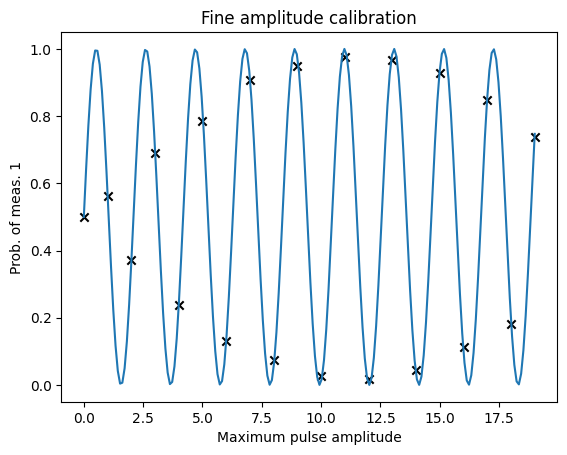

In [183]:
d_theta_x1 = get_d_theta(x1_counts, 0.1)

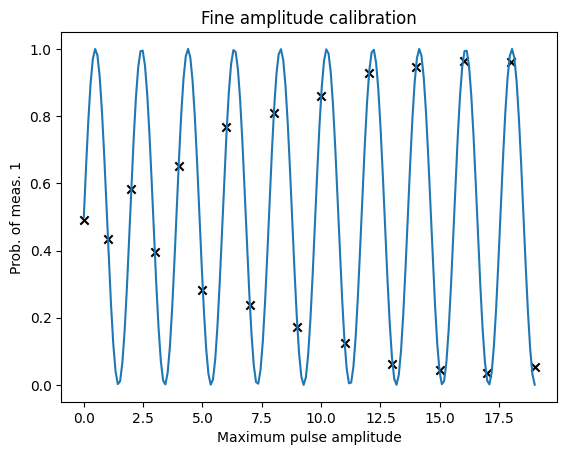

In [184]:
d_theta_x2 = get_d_theta(x2_counts, 0.1)

In [185]:
scale_x1 = (np.pi) / (np.pi + d_theta_x1)
scale_x2 = (np.pi) / (np.pi + d_theta_x2)
scale_x1, scale_x2

(1.0459921148471938, 0.9751309155883242)

In [186]:
fine_x1_amp = rough_x1_amp * scale_x1
fine_x2_amp = rough_x2_amp * scale_x2
fine_x1_amp, fine_x2_amp

(1.8976728685796693, 1.7275757280938093)

In [187]:
cals.add_parameter_value(fine_x1_amp, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(fine_x2_amp, Parameter("amp"), (qubit1,), "x")

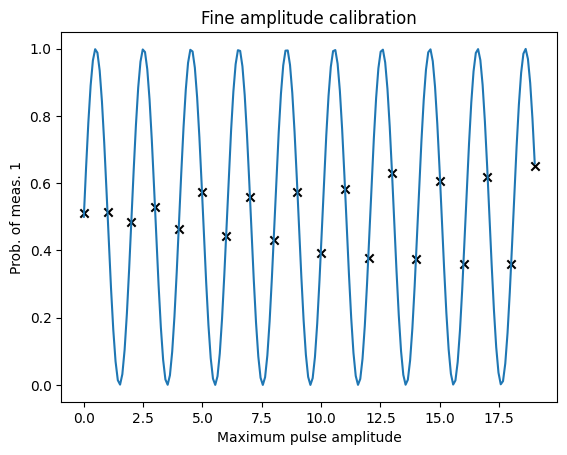

In [188]:
d_theta_x1_gaussian = get_d_theta(x1_counts_gaussian, 0.1)

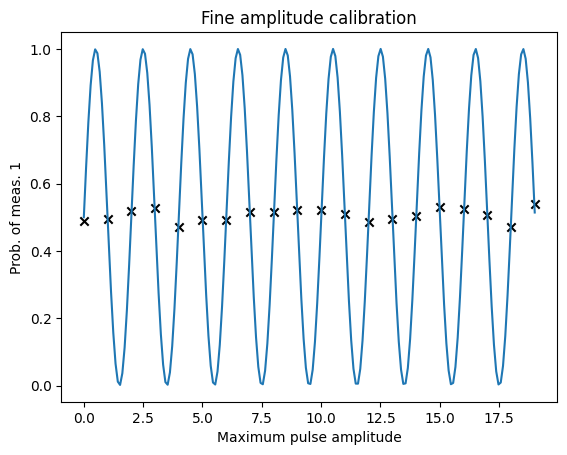

In [189]:
d_theta_x2_gaussian = get_d_theta(x2_counts_gaussian, 0.1)

In [190]:
scale_x1_gaussian = (np.pi) / (np.pi + d_theta_x1_gaussian)
scale_x2_gaussian = (np.pi) / (np.pi + d_theta_x2_gaussian)
scale_x1_gaussian, scale_x2_gaussian

(1.0054527934376094, 1.0004688997037197)

In [191]:
fine_x1_amp_gaussian = rough_x1_amp_gaussian * scale_x1_gaussian
fine_x2_amp_gaussian = rough_x2_amp_gaussian * scale_x2_gaussian
fine_x1_amp_gaussian, fine_x2_amp_gaussian

(1.7333898072689091, 1.7156645475569254)

In [192]:
gaussian_cals.add_parameter_value(fine_x1_amp_gaussian, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(fine_x2_amp_gaussian, Parameter("amp"), (qubit1,), "x")

## Dynamical decoupling sequences

In [193]:
final_x1 = cals.get_schedule("x", (qubit0,))
final_x2 = cals.get_schedule("x", (qubit1,))
final_x1, final_x2

(ScheduleBlock(Play(x(duration=120, amp=1.8976728686, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.7275757281, angle=0), DriveChannel(2)), name="x", transform=AlignLeft()))

In [194]:
final_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
final_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
final_x1_gaussian, final_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.7333898073, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.7156645476, angle=0), DriveChannel(2)), name="x", transform=AlignLeft()))

In [195]:
def xyxy_sequence(
    repetitions: int, 
    num_qubits: int, 
    q0: int, 
    q1: int, 
    schedules = None, 
    edge_qubits: tuple[int, int] = None # (q2, q3), q2 is next to q0 and q3 is next to q1
    ):
    if edge_qubits is not None:
        qc = qk.QuantumCircuit(num_qubits, 4)
        qc.reset(q0)
        qc.reset(q1)
        qc.reset(edge_qubits[0])
        qc.reset(edge_qubits[1])
    else:
        qc = qk.QuantumCircuit(num_qubits, 2)
        qc.reset(q0)
        qc.reset(q1)

    qc.sx(q0)
    qc.sx(q1)
    for _ in range(repetitions):
        qc.x(q0)
        qc.rz(np.pi, q0)
        qc.x(q0)
        qc.x(q0)
        qc.rz(np.pi, q0)
        qc.x(q0)

        qc.x(q1)
        qc.rz(np.pi, q1)
        qc.x(q1)
        qc.x(q1)
        qc.rz(np.pi, q1)
        qc.x(q1)
    qc.sxdg(q0)
    qc.sxdg(q1)
    qc.measure(q0, 0)
    qc.measure(q1, 1)

    # monitor edge qubits
    if edge_qubits is not None:
        qc.measure(edge_qubits[0], 2)
        qc.measure(edge_qubits[1], 3)

    if schedules is not None:
        x_gate = qk.circuit.library.XGate()
        qc.add_calibration(x_gate, (q0,), schedules[0])
        qc.add_calibration(x_gate, (q1,), schedules[1])

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [196]:
num_qubits = backend.num_qubits
num_qubits

127

In [197]:
example = xyxy_sequence(1, num_qubits, qubit0, qubit1)
example.draw(idle_wires=False)

global phase: π
          ┌────┐┌───┐┌───────┐┌───┐┌───┐┌───────┐┌───┐┌─────────┐┌─────────┐»
q_1: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
          ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├─────────┤├─────────┤»
q_2: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
          └────┘└───┘└───────┘└───┘└───┘└───────┘└───┘└─────────┘└─────────┘»
c: 2/═══════════════════════════════════════════════════════════════════════»
                                                                            »
«     ┌────┐┌─────────┐┌─────────┐┌─┐   
«q_1: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├┤M├───
«     ├────┤├─────────┤├─────────┤└╥┘┌─┐
«q_2: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─╫─┤M├
«     └────┘└─────────┘└─────────┘ ║ └╥┘
«c: 2/═════════════════════════════╩══╩═
«                                  0  1

In [206]:
lengths = list(range(0, 201, 4))

In [207]:
dd_circuits_robust = [xyxy_sequence(i, num_qubits, qubit0, qubit1, [final_x1, final_x2]) for i in lengths]
dd_circuits_gaussian = [xyxy_sequence(i, num_qubits, qubit0, qubit1, [final_x1_gaussian, final_x2_gaussian]) for i in lengths]
dd_circuits_default = [xyxy_sequence(i, num_qubits, qubit0, qubit1) for i in lengths]

In [208]:
dd_jobs_robust = sampler.run(dd_circuits_robust, shots=2048)
dd_jobs_gaussian = sampler.run(dd_circuits_gaussian, shots=2048)
dd_jobs_default = sampler.run(dd_circuits_default, shots=2048)

In [209]:
dd_jobs_robust.job_id(), dd_jobs_default.job_id(), dd_jobs_gaussian.job_id()

('ctwm90wv0kkg008q08jg', 'ctwm95cezn20008shne0', 'ctwm91wseb10008x5800')

In [212]:
dd_jobs_robust.status(), dd_jobs_default.status(), dd_jobs_gaussian.status()

('DONE', 'DONE', 'DONE')

In [213]:
dd_jobs_robust = service.job("ctwm90wv0kkg008q08jg")
dd_jobs_default = service.job("ctwm95cezn20008shne0")
dd_jobs_gaussian = service.job("ctwm91wseb10008x5800")

In [214]:
robust_results = dd_jobs_robust.result()
robust_counts = []
robust_counts_q0 = []
robust_counts_q1 = []
for result in robust_results:
    robust_counts.append(result.data.c.get_counts())
    robust_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    robust_counts_q1.append(result.data.c.slice_bits(1).get_counts())

default_results = dd_jobs_default.result()
default_counts = []
default_counts_q0 = []
default_counts_q1 = []
for result in default_results:
    default_counts.append(result.data.c.get_counts())
    default_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    default_counts_q1.append(result.data.c.slice_bits(1).get_counts())


gaussian_results = dd_jobs_gaussian.result()
gaussian_counts = []
gaussian_counts_q0 = []
gaussian_counts_q1 = []
for result in gaussian_results:
    gaussian_counts.append(result.data.c.get_counts())
    gaussian_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    gaussian_counts_q1.append(result.data.c.slice_bits(1).get_counts())

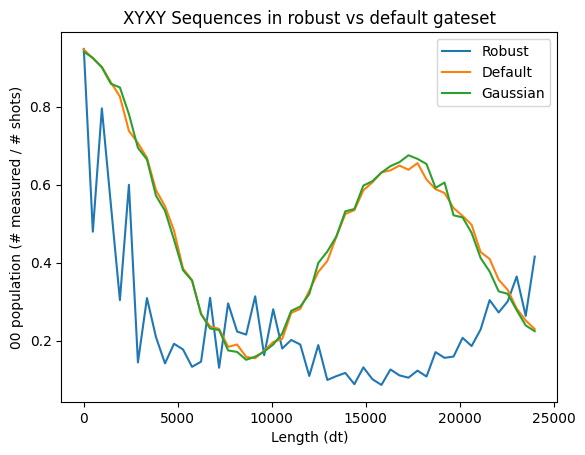

In [219]:
robust_11 = [count.get("00", 0) / 2048 for count in robust_counts]
default_11 = [count.get("00", 0) / 2048 for count in default_counts]
gaussian_11 = [count.get("00", 0) / 2048 for count in gaussian_counts]

plt.plot([l * duration for l in lengths], robust_11, label="Robust")
plt.plot([l * 120 for l in lengths], default_11, label="Default")
plt.plot([l * duration for l in lengths], gaussian_11, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel("00 population (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

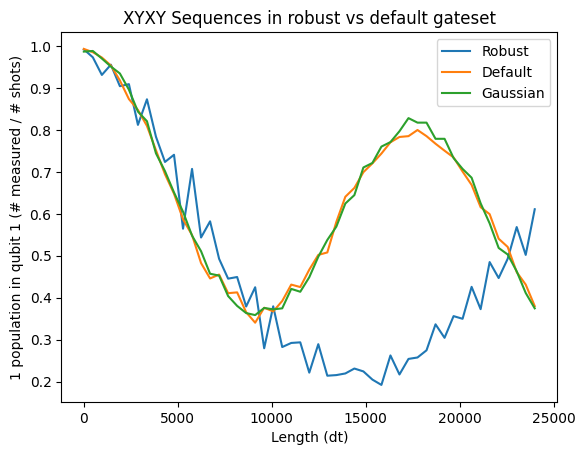

In [221]:
robust_1 = [count.get("0", 0) / 2048 for count in robust_counts_q0]
default_1 = [count.get("0", 0)  / 2048 for count in default_counts_q0]
gaussian_1 = [count.get("0", 0)  / 2048 for count in gaussian_counts_q0]

plt.plot([l * duration for l in lengths], robust_1, label="Robust")
plt.plot([l * 120 for l in lengths], default_1, label="Default")
plt.plot([l * duration for l in lengths], gaussian_1, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel(f"1 population in qubit {qubit0} (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

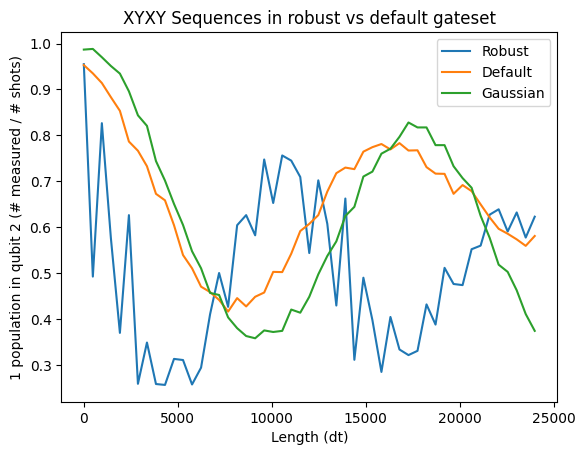

In [222]:
robust_1= [count.get("0", 0) / 2048 for count in robust_counts_q1]
default_1 = [count.get("0", 0)  / 2048 for count in default_counts_q1]

plt.plot([l * duration for l in lengths], robust_1, label="Robust")
plt.plot([l * 120 for l in lengths], default_1, label="Default")
plt.plot([l * duration for l in lengths], gaussian_1, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel(f"1 population in qubit {qubit1} (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()